# El Titanic: un EDA por tu cuenta

El Titanic se hundió en la noche del 14 al 15 de abril de 1912, en su primer viaje. En datos/titanic.csv tienes 891 de sus pasajeros, y de cada uno sabemos, entre otras cosas, en qué clase viajaba y si sobrevivió.

Esta vez el EDA lo haces tú, con las mismas 9 preguntas del jueves. Cuando el resultado de un paso es un número, lo tienes debajo para que compruebes si vas bien. Si no te acuerdas de cómo se hacía algo, mira eda.ipynb (los ejercicios de los pisos son casi iguales) o teoria_eda.ipynb.

Cuando acabes cada bloque, escríbelo en el chat ("Titanic 1", "Titanic 2"...).

## Los datos

| Columna | Nombre en español | Qué es |
|---|---|---|
| PassengerId | id | número del pasajero |
| Survived | sobrevivio | 1 si sobrevivió, 0 si no |
| Pclass | clase | 1 primera, 2 segunda, 3 tercera |
| Name | nombre | nombre del pasajero |
| Sex | sexo | male (hombre) o female (mujer) |
| Age | edad | años. Los bebés tienen decimales: 0.42 son unos 5 meses |
| SibSp | hermanos_pareja | hermanos y pareja que viajaban con él |
| Parch | padres_hijos | padres e hijos que viajaban con él |
| Ticket | | código del billete |
| Fare | precio | lo que pagó, en libras de 1912 |
| Cabin | cabina | número de camarote |
| Embarked | puerto | dónde subió al barco: S Southampton (Inglaterra), C Cherburgo (Francia), Q Queenstown (Irlanda) |

## 0. Comprobación

In [1]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. Primer vistazo

Igual que con los pisos, empieza por ver qué hay en la tabla.

**1.1** Carga datos/titanic.csv en una tabla que se llame titanic y enseña las primeras filas.

In [2]:
titanic = pd.read_csv("datos/titanic.csv")
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**1.2** ¿Cuántas filas y columnas tiene?

Resultado esperado: (891, 12)

In [3]:
print(titanic.shape)

(891, 12)


**1.3** Mira el info(). ¿Qué columnas tienen huecos?

Resultado esperado: Age, Cabin y Embarked

In [4]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


**1.4** Esta vez no elijas las columnas con las que te quedas. Quita la que sobra, Ticket, que es el código del billete y no nos sirve.

Resultado esperado: 11 columnas

In [5]:
titanic = titanic.drop(columns=["Ticket"])
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,NaN,S


**1.5** Ponles los nombres en español, en este orden: id, sobrevivio, clase, nombre, sexo, edad, hermanos_pareja, padres_hijos, precio, cabina y puerto.

In [6]:
titanic.columns = ["id", "sobrevivio", "clase", "nombre", "sexo", "edad",
                   "hermanos_pareja", "padres_hijos", "precio", "cabina", "puerto"]
titanic.head()

,id,sobrevivio,clase,nombre,sexo,edad,hermanos_pareja,padres_hijos,precio,cabina,puerto
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,NaN,S


## 2. Los huecos

Cuenta lo que falta y decide qué haces con cada columna, como hiciste con la licencia y el precio de los pisos.

**2.1** Cuenta los huecos de cada columna.

Resultado esperado: edad 177, cabina 687 y puerto 2

In [7]:
titanic.isna().sum()

id                   0
sobrevivio           0
clase                0
nombre               0
sexo                 0
edad               177
hermanos_pareja      0
padres_hijos         0
precio               0
cabina             687
puerto               2
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

Resultado esperado: edad 19.9, cabina 77.1 y puerto 0.2

In [8]:
porcentaje = titanic.isna().sum() / len(titanic) * 100
porcentaje.round(1)

id                  0.0
sobrevivio          0.0
clase               0.0
nombre              0.0
sexo                0.0
edad               19.9
hermanos_pareja     0.0
padres_hijos        0.0
precio              0.0
cabina             77.1
puerto              0.2
dtype: float64

**2.3** A la cabina le falta casi todo. Decide qué haces con ella, hazlo y mira cuántas filas y columnas quedan.

Resultado esperado: (891, 10)

In [9]:
titanic = titanic.drop(columns=["cabina"])
print(titanic.shape)

(891, 10)


**2.4** Al puerto le faltan solo 2. Quita esas filas.

Resultado esperado: (889, 10)

In [10]:
titanic = titanic.dropna(subset=["puerto"])
print(titanic.shape)

(889, 10)


**2.5** A la edad le falta el 20 %, que es mucho para quitar esas filas. Rellénala con la mediana y comprueba que ya no queda ningún hueco.

Resultado esperado: La mediana es 28.0 y después todo a 0

In [11]:
mediana = titanic["edad"].median()
print("Mediana:", mediana)
titanic["edad"] = titanic["edad"].fillna(mediana)
titanic.isna().sum()

Mediana: 28.0


id                 0
sobrevivio         0
clase              0
nombre             0
sexo               0
edad               0
hermanos_pareja    0
padres_hijos       0
precio             0
puerto             0
dtype: int64

**2.6** Mira con value_counts qué valores hay en sexo y en puerto. ¿Hay algún hueco disfrazado?

Resultado esperado: male 577 y female 312. S 644, C 168 y Q 77. No hay ninguno

In [12]:
print(titanic["sexo"].value_counts())
print(titanic["puerto"].value_counts())

sexo
male      577
female    312
Name: count, dtype: int64
puerto
S    644
C    168
Q     77
Name: count, dtype: int64


## 3. Los duplicados

Comprueba si hay algún pasajero repetido.

**3.1** ¿Cuántas filas repetidas hay?

Resultado esperado: 0

In [13]:
print("Filas repetidas:", titanic.duplicated().sum())

Filas repetidas: 0


**3.2** ¿Y nombres repetidos?

Resultado esperado: 0

In [14]:
print("Nombres repetidos:", titanic["nombre"].duplicated().sum())

Nombres repetidos: 0


**3.3** Quita las columnas id y nombre solo para mirar, sin guardarlo, y cuenta otra vez las filas repetidas. ¿Son la misma persona? Contesta en el chat si las borrarías.

Resultado esperado: 116

In [15]:
print("Iguales sin id ni nombre:", titanic.drop(columns=["id", "nombre"]).duplicated().sum())

Iguales sin id ni nombre: 116


## 4. Los números

Toca mirar los números con el describe, la media, la mediana y un par de histogramas.

**4.1** Haz el describe. ¿Qué te llama la atención de la edad y del precio?

Resultado esperado: La edad va de 0.42 a 80 y el precio, de 0 a 512.33

In [16]:
titanic.describe()

,id,sobrevivio,clase,edad,hermanos_pareja,padres_hijos,precio
count,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000
mean,446.000000,0.382452,2.311586,29.315152,0.524184,0.382452,32.096681
std,256.998173,0.486260,0.834700,12.984932,1.103705,0.806761,49.697504
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,224.000000,0.000000,2.000000,22.000000,0.000000,0.000000,7.895800
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.000000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**4.2** Saca la media y la mediana del precio. ¿Por qué crees que son tan distintas?

Resultado esperado: 32.1 y 14.5

In [17]:
print("Precio medio:", round(titanic["precio"].mean(), 1))
print("Precio mediano:", round(titanic["precio"].median(), 1))

Precio medio: 32.1
Precio mediano: 14.5


**4.3** Dibuja el histograma del precio.

<Axes: ylabel='Frequency'>

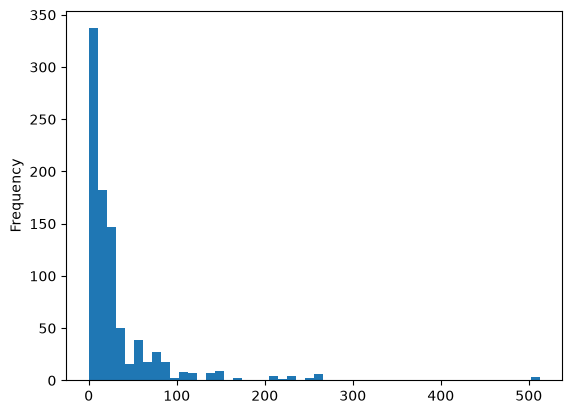

In [18]:
titanic["precio"].plot(kind="hist", bins=50)

**4.4** Saca la media y la mediana de la edad.

Resultado esperado: 29.3 y 28.0

In [19]:
print("Edad media:", round(titanic["edad"].mean(), 1))
print("Edad mediana:", titanic["edad"].median())

Edad media: 29.3
Edad mediana: 28.0


**4.5** Dibuja el histograma de la edad con bins=40. ¿Hay alguna barra que sobresalga? ¿De dónde sale? Piensa en lo que hiciste en el 2.5.

<Axes: ylabel='Frequency'>

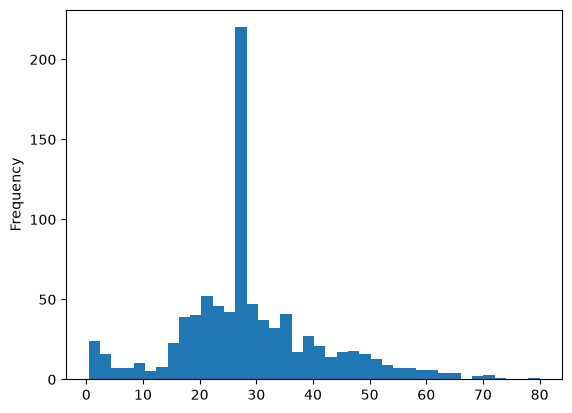

In [20]:
titanic["edad"].plot(kind="hist", bins=40)

## 5. Los valores raros

Busca los valores extremos y decide si son errores o casos reales. En el Titanic hay de los dos.

**5.1** Enseña los 5 billetes más caros.

Resultado esperado: Tres pasajeros de primera pagaron 512.33 libras

In [21]:
titanic.sort_values("precio", ascending=False).head(5)

,id,sobrevivio,clase,nombre,sexo,edad,hermanos_pareja,padres_hijos,precio,puerto
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,512.3292,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,512.3292,C
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,512.3292,C
341,342,1,1,"Fortune, Miss. Alice Elizabeth",female,24.0,3,2,263.0000,S
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,263.0000,S


**5.2** ¿Cuántos pasajeros pagaron 0? Enséñalos.

Resultado esperado: 15, todos hombres

In [22]:
gratis = titanic[titanic["precio"] == 0]
print("Pagaron 0:", len(gratis))
gratis

Pagaron 0: 15


,id,sobrevivio,clase,nombre,sexo,edad,hermanos_pareja,padres_hijos,precio,puerto
179,180,0,3,"Leonard, Mr. Lionel",male,36.0,0,0,0.0,S
263,264,0,1,"Harrison, Mr. William",male,40.0,0,0,0.0,S
271,272,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,0.0,S
277,278,0,2,"Parkes, Mr. Francis ""Frank""",male,28.0,0,0,0.0,S
302,303,0,3,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,0.0,S
413,414,0,2,"Cunningham, Mr. Alfred Fleming",male,28.0,0,0,0.0,S
466,467,0,2,"Campbell, Mr. William",male,28.0,0,0,0.0,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,28.0,0,0,0.0,S
597,598,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,0.0,S
633,634,0,1,"Parr, Mr. William Henry Marsh",male,28.0,0,0,0.0,S


**5.3** ¿Quién es el pasajero de más edad? Busca su nombre en internet y di en el chat cuántos años tenía de verdad.

Resultado esperado: Algernon Barkworth, con 80 años

In [23]:
titanic.sort_values("edad", ascending=False).head(1)

,id,sobrevivio,clase,nombre,sexo,edad,hermanos_pareja,padres_hijos,precio,puerto
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,30.0,S


**5.4** ¿Cuántos pasajeros tienen menos de 1 año? ¿Te parece un error?

Resultado esperado: 7

In [24]:
bebes = titanic[titanic["edad"] < 1]
print("Menos de 1 año:", len(bebes))
bebes

Menos de 1 año: 7


,id,sobrevivio,clase,nombre,sexo,edad,hermanos_pareja,padres_hijos,precio,puerto
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,29.0000,S
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,151.5500,S
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,19.2583,C
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,19.2583,C
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,14.5000,S
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,8.5167,C
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,18.7500,S


**5.5** Haz el diagrama de caja del precio.

<Axes: >

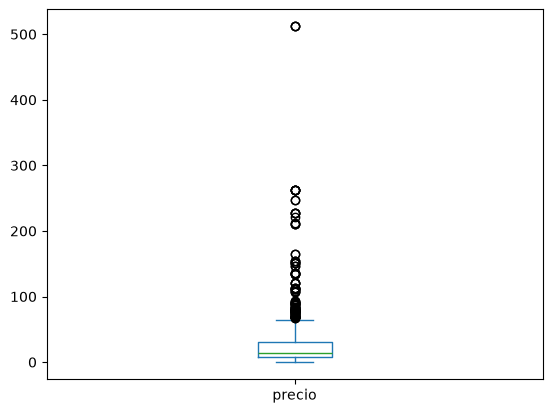

In [25]:
titanic["precio"].plot(kind="box")

**5.6** La edad de Barkworth sí es un error, y ya sabemos cuál es la buena. Corrígela con replace(80, 47). Como es el único pasajero con 80 años, no cambias a nadie más. Comprueba la edad máxima después.

Resultado esperado: 74.0

In [26]:
titanic["edad"] = titanic["edad"].replace(80, 47)
print("Edad máxima:", titanic["edad"].max())

Edad máxima: 74.0


## 6. Las categorías

Cuántos pasajeros hay de cada tipo.

**6.1** ¿Cuántos sobrevivieron? En número y en porcentaje.

Resultado esperado: 340 sobrevivieron, el 38.2 %

In [27]:
print(titanic["sobrevivio"].value_counts())
print((titanic["sobrevivio"].value_counts(normalize=True) * 100).round(1))

sobrevivio
0    549
1    340
Name: count, dtype: int64
sobrevivio
0    61.8
1    38.2
Name: proportion, dtype: float64


**6.2** ¿Cuántos viajaban en cada clase?

Resultado esperado: Tercera 491, primera 214 y segunda 184

In [28]:
titanic["clase"].value_counts()

clase
3    491
1    214
2    184
Name: count, dtype: int64

**6.3** ¿Qué porcentaje eran hombres y qué porcentaje mujeres?

Resultado esperado: male 64.9 y female 35.1

In [29]:
(titanic["sexo"].value_counts(normalize=True) * 100).round(1)

sexo
male      64.9
female    35.1
Name: proportion, dtype: float64

**6.4** Dibuja en barras cuántos pasajeros subieron en cada puerto.

<Axes: xlabel='puerto'>

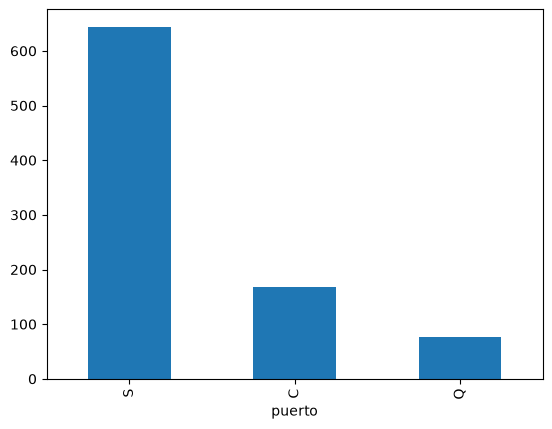

In [30]:
titanic["puerto"].value_counts().plot(kind="bar")

## 7. Comparar grupos

Aquí es donde se ve quién se salvó y quién no.

**7.1** ¿Qué porcentaje sobrevivió de cada sexo?

Resultado esperado: female 74.0 y male 18.9

In [31]:
(titanic.groupby("sexo")["sobrevivio"].mean() * 100).round(1)

sexo
female    74.0
male      18.9
Name: sobrevivio, dtype: float64

**7.2** ¿Y de cada clase?

Resultado esperado: Primera 62.6, segunda 47.3 y tercera 24.2

In [32]:
(titanic.groupby("clase")["sobrevivio"].mean() * 100).round(1)

clase
1    62.6
2    47.3
3    24.2
Name: sobrevivio, dtype: float64

**7.3** ¿Cuánto costaba de mediana el billete en cada clase?

Resultado esperado: Primera 58.69, segunda 14.25 y tercera 8.05

In [33]:
titanic.groupby("clase")["precio"].median()

clase
1    58.6896
2    14.2500
3     8.0500
Name: precio, dtype: float64

**7.4** ¿Se salvaron más los niños? Quédate con los menores de 12 años y calcula qué porcentaje sobrevivió.

Resultado esperado: 68 niños y sobrevivió el 57.4 %

In [34]:
ninos = titanic[titanic["edad"] < 12]
print("Niños:", len(ninos))
print("Sobrevivieron:", round(ninos["sobrevivio"].mean() * 100, 1), "%")

Niños: 68
Sobrevivieron: 57.4 %


**7.5** ¿Y según el puerto donde subieron? ¿Crees que embarcar en Cherburgo (C) te salvaba la vida? Mira qué clases subieron en cada puerto antes de contestar en el chat.

Resultado esperado: C 55.4, Q 39.0 y S 33.7. En Cherburgo, 85 de los 168 eran de primera

In [35]:
print((titanic.groupby("puerto")["sobrevivio"].mean() * 100).round(1))
print(titanic[titanic["puerto"] == "C"]["clase"].value_counts())

puerto
C    55.4
Q    39.0
S    33.7
Name: sobrevivio, dtype: float64
clase
1    85
3    66
2    17
Name: count, dtype: int64


## 8. Relaciones entre columnas

¿Van juntas dos columnas?

**8.1** ¿Tienen relación el precio y sobrevivir? Calcula la correlación.

Resultado esperado: 0.26

In [36]:
print("Precio y sobrevivir:", round(titanic["precio"].corr(titanic["sobrevivio"]), 2))

Precio y sobrevivir: 0.26


**8.2** ¿Y la edad y sobrevivir?

Resultado esperado: -0.07

In [37]:
print("Edad y sobrevivir:", round(titanic["edad"].corr(titanic["sobrevivio"]), 2))

Edad y sobrevivir: -0.07


**8.3** Haz el gráfico de puntos de la edad y el precio, con s=5.

<Axes: xlabel='edad', ylabel='precio'>

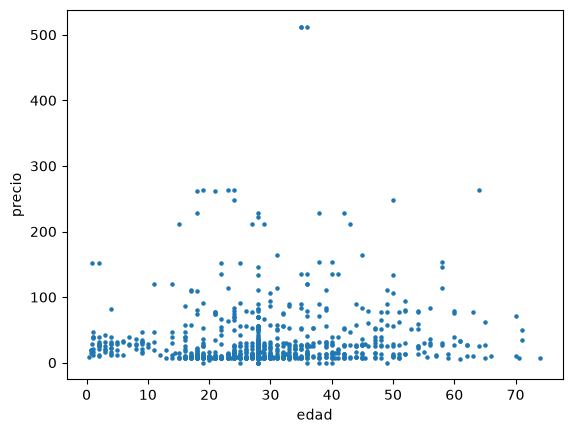

In [38]:
titanic.plot(kind="scatter", x="edad", y="precio", s=5)

## 9. Conclusiones

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos sobre el Titanic, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos.

1. Sobrevivió el 74 % de las mujeres y solo el 19 % de los hombres.
2. La clase importó mucho: se salvó el 63 % de primera y el 24 % de tercera, donde el billete costaba siete veces menos.
3. Parece que subir en Cherburgo salvaba (55 %), pero es porque allí la mitad de los pasajeros eran de primera.

Lo que he cambiado: he quitado la columna de la cabina (77 % vacía) y 2 pasajeros sin puerto, he rellenado 177 edades con la mediana (28) y he corregido la edad de Barkworth (80 → 47).

## Si acabas antes

**10.1** Crea una columna nueva, familia, que sea hermanos_pareja + padres_hijos. ¿Cuál es la familia más grande?

Resultado esperado: 10

In [39]:
titanic["familia"] = titanic["hermanos_pareja"] + titanic["padres_hijos"]
print("Familia más grande:", titanic["familia"].max())

Familia más grande: 10


**10.2** ¿Qué porcentaje sobrevivió de los que viajaban solos (familia 0)? ¿Y de los que iban con alguien?

Resultado esperado: Solos 30.1 y acompañados 50.6

In [40]:
solos = titanic[titanic["familia"] == 0]
acompanados = titanic[titanic["familia"] > 0]
print("Solos:", round(solos["sobrevivio"].mean() * 100, 1), "%")
print("Acompañados:", round(acompanados["sobrevivio"].mean() * 100, 1), "%")

Solos: 30.1 %
Acompañados: 50.6 %


**10.3** Calcula la supervivencia por clase y sexo a la vez. Se hace igual que siempre, pero pasando a groupby una lista con las dos columnas: groupby(["clase", "sexo"]).

Resultado esperado: Mujeres de primera 96.7 y hombres de tercera 13.5

In [41]:
(titanic.groupby(["clase", "sexo"])["sobrevivio"].mean() * 100).round(1)

clase  sexo  
1      female    96.7
       male      36.9
2      female    92.1
       male      15.7
3      female    50.0
       male      13.5
Name: sobrevivio, dtype: float64